<a href="https://colab.research.google.com/github/LywinFM/All-New/blob/main/DA_Ass_2_RFR.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Saving dataset for assignment 2-0426.csv to dataset for assignment 2-0426 (3).csv
Dataset Shape:
(5299, 8)

First 5 Records:


,User ID,Gender,Age,Activity Level,Location,App Sessions,Distance Travelled (km),Calories Burned
0,1,Female,22,Active,Suburban,151.0,140.0,728
1,2,Male,50,Active,Rural,157.0,115.0,523
2,3,Male,36,Active,Urban,178.0,163.0,795
3,4,Female,36,Active,Suburban,155.0,85.0,715
4,5,Male,34,Sedentary,Rural,95.0,71.0,439



Missing Values:
User ID                    0
Gender                     0
Age                        0
Activity Level             0
Location                   0
App Sessions               1
Distance Travelled (km)    1
Calories Burned            0
dtype: int64

Model Performance
MAE  : 93.25
MSE  : 13501.34
RMSE : 116.20
R²   : 0.6049


,Actual,Predicted
4900,364,326.677998
3487,533,531.278595
653,446,515.209203
296,474,570.072631
3075,415,480.135352
4239,213,170.593224
4705,214,400.138666
747,383,330.747546
3686,499,357.018514
1029,730,496.858409


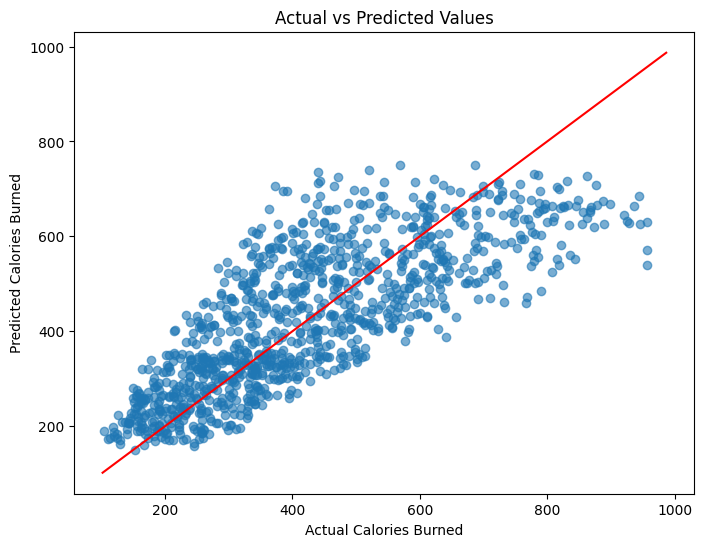


Feature Importance:


,Feature,Importance
10,App Sessions,0.718542
8,User ID,0.095402
11,Distance Travelled (km),0.079808
9,Age,0.070903
7,Location_Urban,0.007939
5,Location_Rural,0.007496
6,Location_Suburban,0.007329
1,Gender_Male,0.005772
0,Gender_Female,0.005688
3,Activity Level_Moderate,0.000507


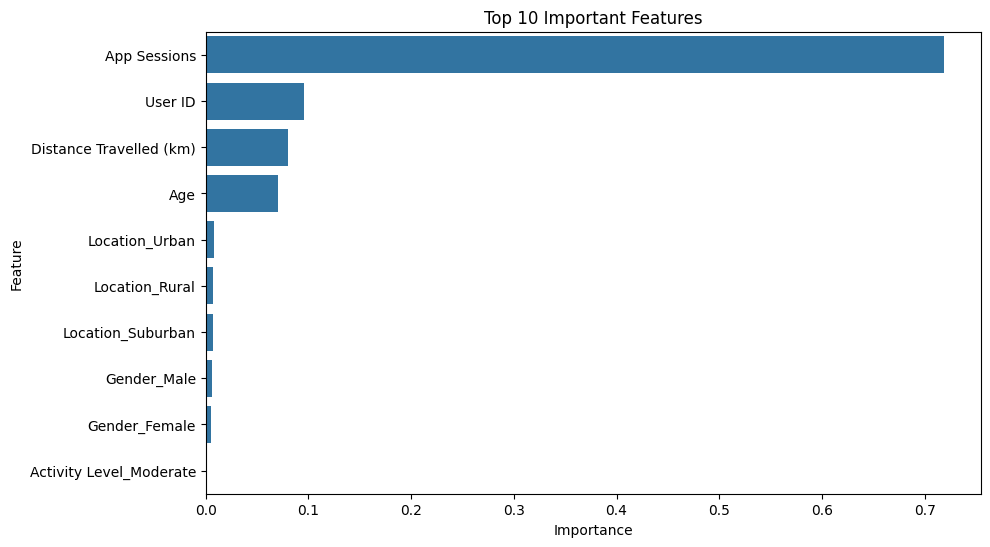

In [ ]:
# ======================================================
# RANDOM FOREST REGRESSION
# Predicting Calories Burned
# ======================================================

# Install and Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# ======================================================
# STEP 1: Upload Dataset
# ======================================================

uploaded = files.upload()

# Updated to match the actual file name present in the workspace
df = pd.read_csv('dataset for assignment 2-0426.csv')

print("Dataset Shape:")
print(df.shape)

print("\nFirst 5 Records:")
display(df.head())

# ======================================================
# STEP 2: Check Missing Values
# ======================================================

print("\nMissing Values:")
print(df.isnull().sum())

# ======================================================
# STEP 3: Define Features and Target
# ======================================================

X = df.drop(['Calories Burned'], axis=1)

y = df['Calories Burned']

# ======================================================
# STEP 4: Identify Categorical and Numerical Columns
# ======================================================

categorical_features = [
    'Gender',
    'Activity Level',
    'Location'
]

numeric_features = [
    'User ID',
    'Age',
    'App Sessions',
    'Distance Travelled (km)'
]

# ======================================================
# STEP 5: Preprocessing
# ======================================================

preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore'),
         categorical_features),
        ('num', 'passthrough',
         numeric_features)
    ]
)

# ======================================================
# STEP 6: Build Random Forest Model
# ======================================================

model = RandomForestRegressor(
    n_estimators=200,
    max_depth=15,
    random_state=42
)

pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', model)
])

# ======================================================
# STEP 7: Split Dataset
# ======================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

# ======================================================
# STEP 8: Train Model
# ======================================================

pipeline.fit(X_train, y_train)

# ======================================================
# STEP 9: Predict
# ======================================================

y_pred = pipeline.predict(X_test)

# ======================================================
# STEP 10: Model Evaluation
# ======================================================

mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

print("\nModel Performance")
print("="*50)

print(f"MAE  : {mae:.2f}")
print(f"MSE  : {mse:.2f}")
print(f"RMSE : {rmse:.2f}")
print(f"R²   : {r2:.4f}")

# ======================================================
# STEP 11: Actual vs Predicted
# ======================================================

results = pd.DataFrame({
    'Actual': y_test,
    'Predicted': y_pred
})

display(results.head(10))

# ======================================================
# STEP 12: Scatter Plot
# ======================================================

plt.figure(figsize=(8,6))

plt.scatter(
    y_test,
    y_pred,
    alpha=0.6
)

plt.plot(
    [y.min(), y.max()],
    [y.min(), y.max()],
    color='red'
)

plt.xlabel('Actual Calories Burned')
plt.ylabel('Predicted Calories Burned')
plt.title('Actual vs Predicted Values')

plt.show()

# ======================================================
# STEP 13: Feature Importance
# ======================================================

ohe = pipeline.named_steps['preprocessor']\
              .named_transformers_['cat']

cat_names = ohe.get_feature_names_out(
    categorical_features
)

feature_names = np.concatenate([
    cat_names,
    numeric_features
])

importance = pipeline.named_steps['model']\
                     .feature_importances_

feature_importance = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importance
})

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

print("\nFeature Importance:")
display(feature_importance)

# ======================================================
# STEP 14: Plot Feature Importance
# ======================================================

plt.figure(figsize=(10,6))

sns.barplot(
    data=feature_importance.head(10),
    x='Importance',
    y='Feature'
)

plt.title('Top 10 Important Features')
plt.show()